<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QFT Ch 2 Figures — Colab Notebook
**Quantum Field Theory · Chapter 2: Canonical Quantization**

PSE Lab · SeoulTech · Tong (Cambridge)

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | QHO levels, ladder operators, field mode spectrum | §2.1–2.2 |
| fig02 | Vacuum fluctuations, zero-point energy, normal ordering | §2.3 |
| fig03 | Fock space, occupation numbers, multi-particle spectrum | §2.4 |
| fig04 | Feynman propagator, position-space decay, causality | §2.5–2.6 |

---
## fig01 · QHO & Field Mode Spectrum (§2.1–2.2)

**Left**: QHO energy levels $E_n=(n+\frac{1}{2})\omega$ with wavefunctions. **Centre**: Ladder operators $a^\dagger,a$ acting on $|n\rangle$. **Right**: Field mode spectrum $\omega_\mathbf{k}=\sqrt{k^2+m^2}$ — each mode is an independent QHO.

  saved -> figures/ch02/fig01_qho_modes.png


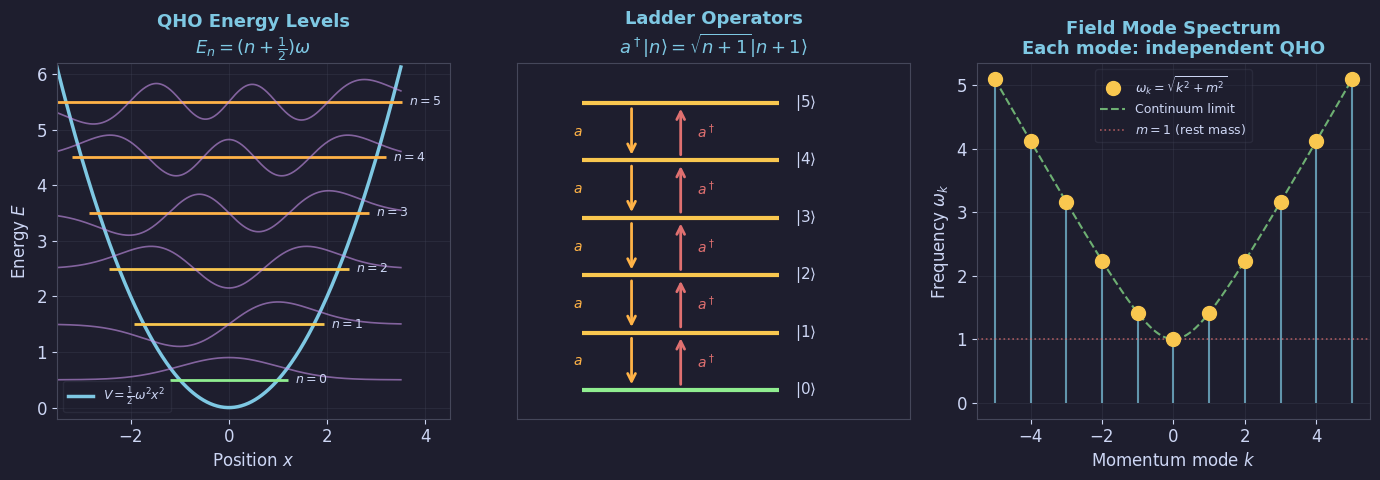

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch02'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig01: QHO energy levels + mode spectrum ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: QHO potential + energy levels
ax = axes[0]
x = np.linspace(-3.5, 3.5, 400)
V = 0.5 * x**2
ax.plot(x, V, color=BLUE, lw=2.5, label=r'$V=\frac{1}{2}\omega^2 x^2$')
for n in range(6):
    E = n + 0.5
    mask = V <= E + 0.05
    ax.hlines(E, -np.sqrt(2*E)-0.2, np.sqrt(2*E)+0.2,
              colors=GREEN if n == 0 else YELLOW if n < 3 else ORANGE,
              lw=2.0)
    ax.text(np.sqrt(2*E)+0.35, E, f'$n={n}$', va='center', color=FG, fontsize=9)
    psi = np.zeros_like(x)
    from numpy.polynomial.hermite import hermval
    coeffs = [0]*n + [1]
    H = hermval(x, coeffs)
    psi_raw = H * np.exp(-x**2/2)
    psi_norm = psi_raw / (np.max(np.abs(psi_raw)) + 1e-10) * 0.4
    ax.plot(x, psi_norm + E, color=PURPLE, lw=1.2, alpha=0.6)
ax.set_xlabel('Position $x$'); ax.set_ylabel('Energy $E$')
ax.set_title('QHO Energy Levels\n' + r'$E_n=(n+\frac{1}{2})\omega$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-3.5, 4.5); ax.set_ylim(-0.2, 6.2)

# Centre: ladder operators action
ax2 = axes[1]
levels = np.arange(6)
for n in levels:
    col = GREEN if n == 0 else YELLOW
    ax2.hlines(n + 0.5, 0.2, 0.8, colors=col, lw=3.0)
    ax2.text(0.85, n + 0.5, f'$|{n}\\rangle$', va='center', color=FG, fontsize=11)
for n in range(5):
    ax2.annotate('', xy=(0.5, n+1.5-0.05), xytext=(0.5, n+0.5+0.05),
                 arrowprops=dict(arrowstyle='->', color=RED, lw=2.0, mutation_scale=14))
    ax2.text(0.55, n+1.0, r'$a^\dagger$', color=RED, fontsize=10, va='center')
    ax2.annotate('', xy=(0.35, n+0.5+0.05), xytext=(0.35, n+1.5-0.05),
                 arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0, mutation_scale=14))
    ax2.text(0.17, n+1.0, r'$a$', color=ORANGE, fontsize=10, va='center')
ax2.set_xlim(0, 1.2); ax2.set_ylim(0, 6.2)
ax2.set_yticks([]); ax2.set_xticks([])
ax2.set_title('Ladder Operators\n' + r'$a^\dagger|n\rangle=\sqrt{n+1}|n+1\rangle$', color=BLUE)
ax2.grid(False)

# Right: field mode frequencies (discretised k-space)
ax3 = axes[2]
k_vals = np.arange(-5, 6)
omega_k = np.sqrt(k_vals**2 + 1.0)
markersize = 10
ax3.vlines(k_vals, 0, omega_k, colors=BLUE, lw=1.5, alpha=0.7)
ax3.plot(k_vals, omega_k, 'o', color=YELLOW, ms=markersize, zorder=5,
         label=r'$\omega_k=\sqrt{k^2+m^2}$')
k_cont = np.linspace(-5, 5, 300)
ax3.plot(k_cont, np.sqrt(k_cont**2 + 1.0), color=GREEN, lw=1.5, ls='--',
         alpha=0.7, label='Continuum limit')
ax3.axhline(1.0, color=RED, lw=1.2, ls=':', alpha=0.7, label='$m=1$ (rest mass)')
ax3.set_xlabel(r'Momentum mode $k$')
ax3.set_ylabel(r'Frequency $\omega_k$')
ax3.set_title('Field Mode Spectrum\n' + r'Each mode: independent QHO', color=BLUE)
ax3.legend(loc="upper center", fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig01_qho_modes.png', fig)


---
## fig02 · Normal Ordering & Vacuum (§2.3)

**Left**: Zero-point energy $\sum_k\frac{1}{2}\omega_k$ diverges — removed by normal ordering. **Centre**: Vacuum fluctuations $\langle 0|\hat\phi^2|0\rangle\neq 0$ even though $\langle\hat\phi\rangle=0$. **Right**: Normal ordering rules $:a^\dagger a + aa^\dagger:=2a^\dagger a$.

  saved -> figures/ch02/fig02_normal_ordering.png


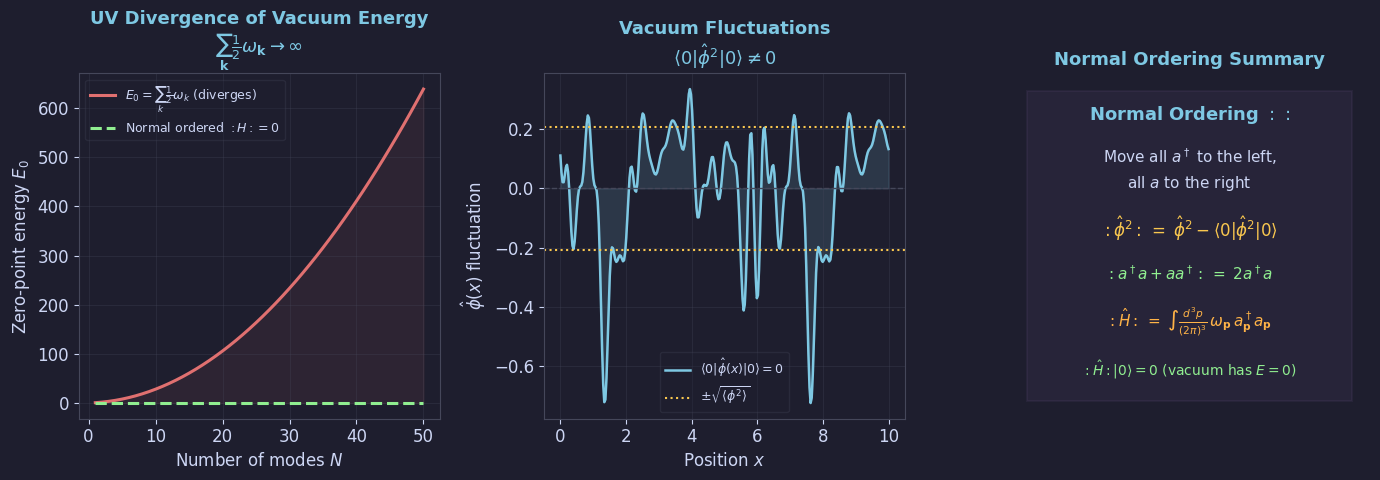

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch02'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig02: Vacuum fluctuations + normal ordering ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: zero-point energy divergence — sum over modes
ax = axes[0]
N_modes = np.arange(1, 51)
E0_raw  = np.cumsum(0.5 * np.sqrt(N_modes**2 + 1.0))
E0_norm = np.zeros(len(N_modes))   # after normal ordering: 0
ax.plot(N_modes, E0_raw,  color=RED,   lw=2.2, label=r'$E_0=\sum_k\frac{1}{2}\omega_k$ (diverges)')
ax.plot(N_modes, E0_norm, color=GREEN, lw=2.2, ls='--', label=r'Normal ordered $:H:=0$')
ax.fill_between(N_modes, 0, E0_raw, color=RED, alpha=0.08)
ax.set_xlabel('Number of modes $N$')
ax.set_ylabel('Zero-point energy $E_0$')
ax.set_title('UV Divergence of Vacuum Energy\n' + r'$\sum_\mathbf{k}\frac{1}{2}\omega_\mathbf{k}\to\infty$',
             color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

# Centre: vacuum fluctuations of phi(x,t)
ax2 = axes[1]
np.random.seed(42)
x = np.linspace(0, 10, 300)
# simulate vacuum fluctuations as sum of random modes
N_fluct = 20
fluct = np.zeros_like(x)
for k in range(1, N_fluct+1):
    omega_k = np.sqrt(k**2 + 1.0)
    amp = 1.0 / np.sqrt(2*omega_k) / np.sqrt(N_fluct)
    phase = np.random.uniform(0, 2*np.pi)
    fluct += amp * np.cos(k*x + phase)
ax2.plot(x, fluct, color=BLUE, lw=1.8, label=r'$\langle 0|\hat\phi(x)|0\rangle=0$')
ax2.fill_between(x, fluct, 0, color=BLUE, alpha=0.15)
ax2.axhline(0, color=EDGE, lw=1.0, ls='--')
phi2_vac = np.var(fluct)
ax2.axhline( np.sqrt(phi2_vac), color=YELLOW, lw=1.5, ls=':', label=r'$\pm\sqrt{\langle\phi^2\rangle}$')
ax2.axhline(-np.sqrt(phi2_vac), color=YELLOW, lw=1.5, ls=':')
ax2.set_xlabel('Position $x$')
ax2.set_ylabel(r'$\hat\phi(x)$ fluctuation')
ax2.set_title('Vacuum Fluctuations\n' + r'$\langle 0|\hat\phi^2|0\rangle\neq 0$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: normal ordering diagram
ax3 = axes[2]
ax3.axis('off')
items = [
    (0.5, 0.88, r'Normal Ordering $:\,:$', BLUE, 13, 'bold'),
    (0.5, 0.76, r'Move all $a^\dagger$ to the left,', FG, 11, 'normal'),
    (0.5, 0.68, r'all $a$ to the right', FG, 11, 'normal'),
    (0.5, 0.55, r'$:\hat\phi^2: \;=\; \hat\phi^2 - \langle 0|\hat\phi^2|0\rangle$', YELLOW, 12, 'normal'),
    (0.5, 0.42, r'$:a^\dagger a + aa^\dagger: \;=\; 2a^\dagger a$', GREEN, 11, 'normal'),
    (0.5, 0.28, r'$:\hat H: \;=\; \int \frac{d^3p}{(2\pi)^3}\,\omega_\mathbf{p}\,a^\dagger_\mathbf{p}a_\mathbf{p}$',
     ORANGE, 11, 'normal'),
    (0.5, 0.14, r'$:\hat H:|0\rangle = 0$ (vacuum has $E=0$)', GREEN, 10, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax3.text(xp, yp, txt, ha='center', va='center', color=col,
             fontsize=fs, fontweight=fw, transform=ax3.transAxes)
rect = plt.Rectangle((0.05, 0.05), 0.90, 0.90,
                      fill=True, facecolor=PURPLE, alpha=0.06,
                      edgecolor=PURPLE, lw=1.5, transform=ax3.transAxes)
ax3.add_patch(rect)
ax3.set_title('Normal Ordering Summary', color=BLUE)

plt.tight_layout(pad=1.2)
save('fig02_normal_ordering.png', fig)


---
## fig03 · Fock Space & Particle Interpretation (§2.4)

**Left**: Fock space sectors — vacuum, 1-particle, 2-particle, ... **Centre**: Occupation number representation $n_\mathbf{k}$ for a multi-particle state. **Right**: Single-particle dispersion + 2-particle continuum threshold at $E=2m$.

  saved -> figures/ch02/fig03_fock_space.png


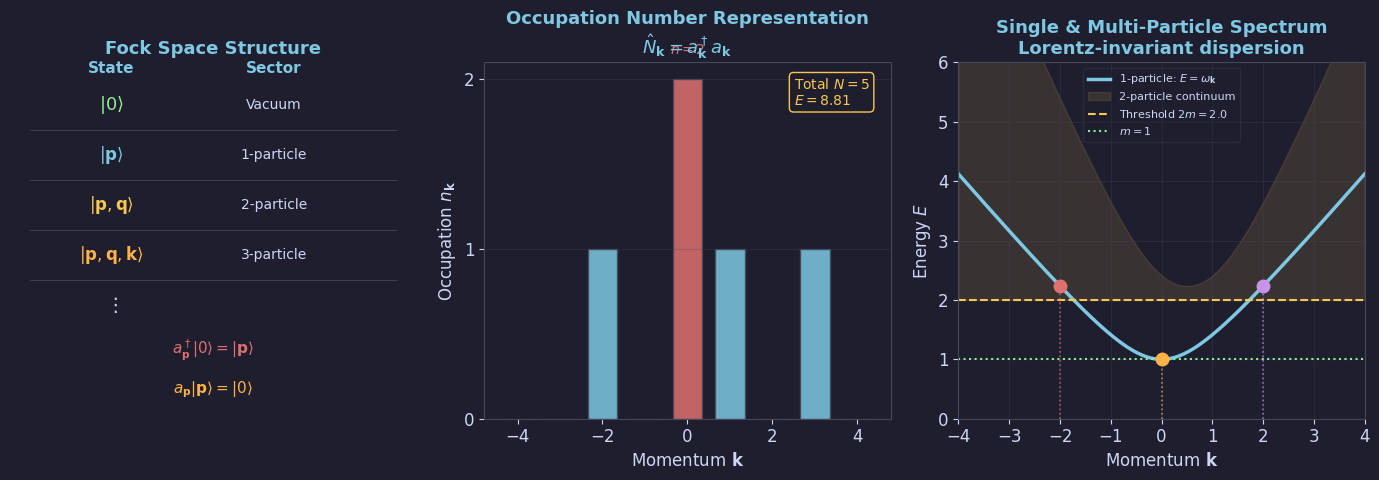

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch02'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig03: Fock space + particle interpretation ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Fock space structure
ax = axes[0]
ax.axis('off')
sectors = [
    (0.50, 0.88, r'$|0\rangle$',              r'Vacuum',              GREEN,  13),
    (0.50, 0.74, r'$|\mathbf{p}\rangle$',      r'1-particle',          BLUE,   12),
    (0.50, 0.60, r'$|\mathbf{p},\mathbf{q}\rangle$', r'2-particle',   YELLOW, 12),
    (0.50, 0.46, r'$|\mathbf{p},\mathbf{q},\mathbf{k}\rangle$', r'3-particle', ORANGE, 12),
    (0.50, 0.32, r'$\vdots$',                  r'',                    FG,     14),
]
for (xp, yp, ket, label, col, fs) in sectors:
    ax.text(0.25, yp, ket,   ha='center', va='center', color=col,    fontsize=fs, transform=ax.transAxes)
    ax.text(0.65, yp, label, ha='center', va='center', color=FG, fontsize=10, transform=ax.transAxes)
ax.text(0.25, 0.97, 'State', ha='center', color=BLUE, fontsize=11, fontweight='bold', transform=ax.transAxes)
ax.text(0.65, 0.97, 'Sector', ha='center', color=BLUE, fontsize=11, fontweight='bold', transform=ax.transAxes)
ax.text(0.50, 0.18, r'$a^\dagger_\mathbf{p}|0\rangle = |\mathbf{p}\rangle$',
        ha='center', color=RED, fontsize=11, transform=ax.transAxes)
ax.text(0.50, 0.07, r'$a_\mathbf{p}|\mathbf{p}\rangle = |0\rangle$',
        ha='center', color=ORANGE, fontsize=11, transform=ax.transAxes)
for yp in [0.81, 0.67, 0.53, 0.39]:
    ax.plot([0.05, 0.95], [yp, yp], color=EDGE, lw=0.6, transform=ax.transAxes)

ax.set_title('Fock Space Structure', color=BLUE)

# Centre: momentum-space occupation (multi-particle state)
ax2 = axes[1]
k_vals = np.arange(-4, 5)
n_k = np.array([0,0,1,0,2,1,0,1,0])
colors_bar = [GREEN if n==0 else BLUE if n==1 else RED for n in n_k]
bars = ax2.bar(k_vals, n_k, color=colors_bar, edgecolor=EDGE, lw=1.0, width=0.7, alpha=0.85)
ax2.set_xlabel(r'Momentum $\mathbf{k}$')
ax2.set_ylabel(r'Occupation $n_\mathbf{k}$')
ax2.set_yticks([0,1,2])
ax2.set_title('Occupation Number Representation\n' + r'$\hat N_\mathbf{k}=a^\dagger_\mathbf{k}a_\mathbf{k}$',
              color=BLUE)
ax2.text(0, 2.15, r'$n=2$', ha='center', color=RED, fontsize=10)
total_N = int(np.sum(n_k))
total_E = float(np.sum(n_k * np.sqrt(k_vals**2 + 1.0)))
ax2.text(2.5, 1.85,
         f'Total $N={total_N}$\n$E={total_E:.2f}$',
         color=YELLOW, fontsize=10,
         bbox=dict(facecolor=BG, edgecolor=YELLOW, boxstyle='round,pad=0.3'))
ax2.grid(True, axis='y')

# Right: relativistic dispersion + multi-particle states
ax3 = axes[2]
k_cont = np.linspace(-4, 4, 300)
omega = np.sqrt(k_cont**2 + 1.0)
ax3.plot(k_cont, omega, color=BLUE, lw=2.5, label=r'1-particle: $E=\omega_\mathbf{k}$')
# 2-particle threshold
k2 = np.linspace(-4, 4, 300)
E2_min = 2 * 1.0  # 2m threshold
ax3.fill_between(k2, E2_min, np.sqrt(k2**2+1)+np.sqrt((k2-1)**2+1),
                 color=YELLOW, alpha=0.12, label='2-particle continuum')
ax3.axhline(E2_min, color=YELLOW, lw=1.5, ls='--', label=f'Threshold $2m={E2_min}$')
ax3.axhline(1.0, color=GREEN, lw=1.5, ls=':', label='$m=1$')
for k0_pt, col in [(-2, RED), (0, ORANGE), (2, PURPLE)]:
    E_pt = np.sqrt(k0_pt**2 + 1.0)
    ax3.plot([k0_pt], [E_pt], 'o', color=col, ms=9, zorder=5)
    ax3.vlines(k0_pt, 0, E_pt, colors=col, lw=1.2, ls=':', alpha=0.7)
ax3.set_xlabel(r'Momentum $\mathbf{k}$')
ax3.set_ylabel(r'Energy $E$')
ax3.set_title('Single & Multi-Particle Spectrum\n' + r'Lorentz-invariant dispersion',
              color=BLUE)
ax3.legend(fontsize=8, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(-4, 4); ax3.set_ylim(0, 6)

plt.tight_layout(pad=1.2)
save('fig03_fock_space.png', fig)


---
## fig04 · Feynman Propagator & Causality (§2.5–2.6)

**Left**: Feynman propagator $\tilde\Delta_F(p)=i/(p^2-m^2+i\varepsilon)$ — poles at $p^0=\pm\omega_\mathbf{k}$. **Centre**: Position-space propagator — Yukawa decay (spacelike) vs oscillation (timelike). **Right**: Causality — commutator $[\hat\phi(x),\hat\phi(y)]=0$ for spacelike separation.

  saved -> figures/ch02/fig04_propagator.png


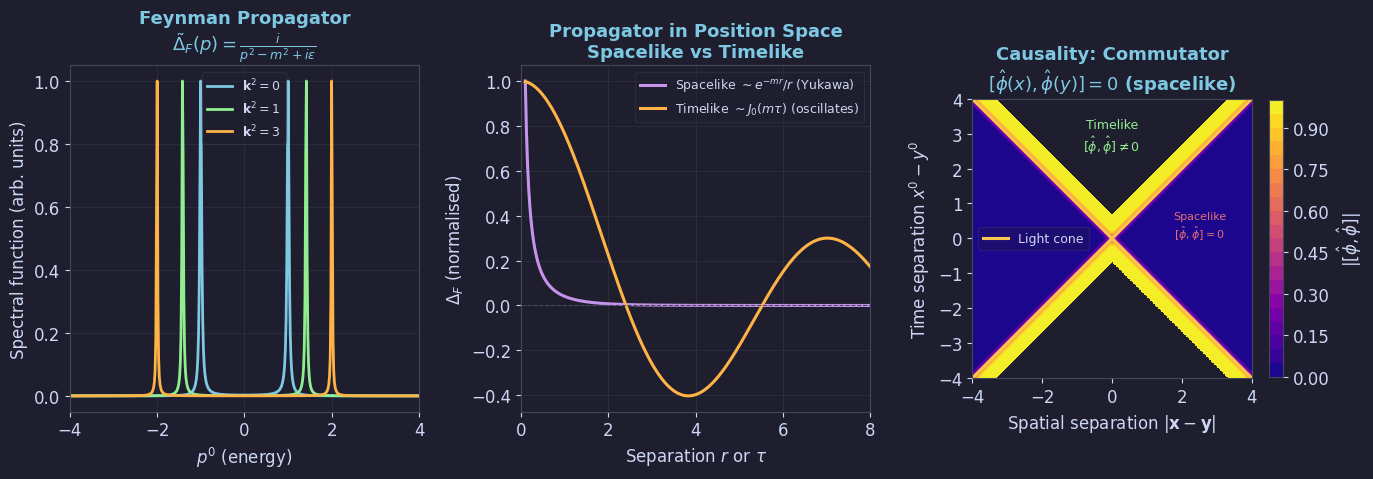

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, y0
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch02'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig04: Propagators + causality ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Feynman propagator in momentum space (Breit-Wigner style)
ax = axes[0]
omega = np.linspace(0, 5, 500)
m = 1.0; eps = 0.05
p0_vals = np.linspace(-4, 4, 500)
# Im part of Feynman propagator ~ delta(p^2 - m^2)
# |G_F(p)| = 1/|p^2 - m^2 + i*eps|
for k2, col, lab in [(0, BLUE, r'$\mathbf{k}^2=0$'),
                     (1, GREEN, r'$\mathbf{k}^2=1$'),
                     (3, ORANGE, r'$\mathbf{k}^2=3$')]:
    denom = (p0_vals**2 - k2 - m**2)**2 + eps**2
    spectral = eps / (np.pi * denom)
    spectral /= spectral.max()
    ax.plot(p0_vals, spectral, color=col, lw=2.0, label=lab)
ax.set_xlabel(r'$p^0$ (energy)')
ax.set_ylabel(r'Spectral function (arb. units)')
ax.set_title('Feynman Propagator\n' + r'$\tilde\Delta_F(p)=\frac{i}{p^2-m^2+i\varepsilon}$',
             color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-4, 4)

# Centre: position-space propagator vs separation
ax2 = axes[1]
r_vals = np.linspace(0.1, 8, 300)
m_val = 1.0
# Yukawa (spacelike, approximate): ~ e^{-mr}/r
# Timelike oscillates
Delta_spacelike = np.exp(-m_val * r_vals) / r_vals
Delta_spacelike /= Delta_spacelike[0]
# Timelike: ~ J_0(m*tau) for large separations
tau_vals = np.linspace(0.1, 8, 300)
Delta_timelike = j0(m_val * tau_vals)

ax2.plot(r_vals,   Delta_spacelike, color=PURPLE, lw=2.2,
         label=r'Spacelike $\sim e^{-mr}/r$ (Yukawa)')
ax2.plot(tau_vals, Delta_timelike,  color=ORANGE,  lw=2.2,
         label=r'Timelike $\sim J_0(m\tau)$ (oscillates)')
ax2.axhline(0, color=EDGE, lw=0.8, ls='--')
ax2.set_xlabel(r'Separation $r$ or $\tau$')
ax2.set_ylabel(r'$\Delta_F$ (normalised)')
ax2.set_title('Propagator in Position Space\n' + r'Spacelike vs Timelike', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 8)

# Right: causality — [phi(x), phi(y)] vanishes for spacelike separation
ax3 = axes[2]
x_sep = np.linspace(-4, 4, 400)
t_sep = np.linspace(-4, 4, 400)
X, T = np.meshgrid(x_sep, t_sep)
# Commutator vanishes outside light cone: timelike = nonzero, spacelike = 0
commutator = np.where(T**2 > X**2, 1.0, 0.0)   # schematic
# smooth the boundary
from scipy.ndimage import gaussian_filter
commutator_smooth = gaussian_filter(commutator.astype(float), sigma=4)
cf = ax3.contourf(X, T, commutator_smooth, levels=20, cmap='plasma')
ax3.plot(x_sep,  abs(x_sep), color=YELLOW, lw=2.2, label='Light cone')
ax3.plot(x_sep, -abs(x_sep), color=YELLOW, lw=2.2)
ax3.text( 0.0,  2.5, 'Timelike\n' + r'$[\hat\phi,\hat\phi]\neq 0$',
          ha='center', color=GREEN, fontsize=9)
ax3.text( 2.5,  0.0, 'Spacelike\n' + r'$[\hat\phi,\hat\phi]=0$',
          ha='center', color=RED, fontsize=8)
ax3.set_xlabel(r'Spatial separation $|\mathbf{x}-\mathbf{y}|$')
ax3.set_ylabel(r'Time separation $x^0-y^0$')
ax3.set_title('Causality: Commutator\n' + r'$[\hat\phi(x),\hat\phi(y)]=0$ (spacelike)',
              color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)
fig.colorbar(cf, ax=ax3, shrink=0.8, label='$|[\\hat\\phi,\\hat\\phi]|$')
ax3.set_xlim(-4, 4); ax3.set_ylim(-4, 4); ax3.set_aspect('equal')

plt.tight_layout(pad=1.2)
save('fig04_propagator.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

# AUTO-INJECTED: Korean font setup for matplotlib
import os as _os
import matplotlib.font_manager as _fm
import matplotlib.pyplot as _plt
if not any('NanumGothic' in f.name for f in _fm.fontManager.ttflist):
    for _font in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
                  '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf']:
        if _os.path.exists(_font):
            _fm.fontManager.addfont(_font)
_plt.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False})
del _os, _fm, _plt
# END AUTO-INJECTED Korean font setup


OUTDIR = 'figures/ch02'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')])
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'qft_ch02_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 4 figures:
  fig01_qho_modes.png  (199 KB)
  fig02_normal_ordering.png  (201 KB)
  fig03_fock_space.png  (150 KB)
  fig04_propagator.png  (227 KB)
Zip: qft_ch02_figures.zip  (738 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>